# Nuages de mots

## Imports et stopwords

In [5]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Ordinateur\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [77]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
# Version 2 : annonces et adresses
sw += ["rue", "avenue", "demande", "prix", "maison", "bon", "bons", "bonne",
       "place", "ecrire", "ecr", "vendre", "louer", "fille", "jeune", "agence"]
# Version 3 : mots génériques et abréviations
sw += ["ans", "très", "heures", "grand", "grande", "francs", "midi", "mois",
       "jour", "jours", "toute", "peu", "etc", "chez", "soir", "matin", "belle",
       "libre", "vend", "femme", "brux", "cour", "cours"]
# Version 4 : annonces restantes et mots génériques
sw += ["adr", "adresser", "bureau", "vente", "présenter", "homme", "dés", "suite",
       "courant", "gros", "avant", "mètres", "leurs", "quelques", "partie",
       "prés", "près", "saint"]
# Version 5 : annonces, débris d'OCR et génériques restants
sw += ["gages", "référ", "demandé", "fem", "chambre", "hôtel", "chaussée",
       "porte", "aveo", "temps", "lieu", "petit"]
sw = set(sw)

## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [78]:
# Choisir une année
year = 1923

In [79]:
txt_path = '../../data/txt'
temp_path = '../../data/tmp'
txts = [f for f in os.listdir(txt_path)
        if f.endswith('.txt') and f.startswith(f"KB_JB838_{year}-")]
len(txts)

100

In [80]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [81]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [82]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"BSwntatH»» fl ùtur wsassamm ggz»SBpi LE SOIR iTfi , T»i»»x5^'8Trarfl»WTMW-txasatggiCLri^cs^'.tgpxzmKy^aa3LaaB 7 JANViHR 1923 »~* IMPERMEABLES* 149. rue Arit--Dansaert ’ — OSTENDE. A louer : 1° l’hôtel"

In [83]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [84]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"BSwntatH»» fl ùtur wsassamm ggz»SBpi LE SOIR iTfi , T»i»»x5^'8Trarfl»WTMW-txasatggiCLri^cs^'.tgpxzmKy^aa3LaaB 7 JANViHR 1923 »~* IMPERMEABLES* 149. rue Arit--Dansaert ’ — OSTENDE. A louer : 1° l’hôtel meublé-et le «àf$?restaurant ! St-Sébasiien : 2° l’exploitation <lè la cour, écuries, remises et garages. Ecrire: vAgeuce de Publicité, 105, rue de la Chapelle. — AUX BELGES S'ARRETANT à STRAS ‘BOURG, il est recommandé de choisir le GRAND •HOTEL NATIONAL, en face gare, maison de tout 1er ordre, de "

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [85]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [86]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1923_clean.txt!'

In [87]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'BSWNTATH ÙTUR WSASSAMM GGZ SBPI ITFI WTMW TXASATGGICLRI TGPXZMKY JANVIHR IMPERMEABLES ARIT DANSAERT OSTENDE MEUBLÉ RESTAURANT SÉBASIIEN EXPLOITATION ÉCURIES REMISES GARAGES VAGEUCE PUBLICITÉ CHAPELLE BELGES ARRETANT STRAS BOURG RECOMMANDÉ CHOISIR HOTEL NATIONAL FACE GARE ORDRE PRÉFÉRÉ COMPATRIOTES SÏCE COTE AZUR DÉP GROUPES SAMEDIS YOYAG NOCES ITALIE CORSE ALGÉRIE VOYAGES BELGES LEMONNIER ECONOMIE VIE CHERE MONNAIE OUVRIRA PALAIS SATIS ÏAIT ACHETANT CHOCOLAT BARON CACAO BENSDORP EXPOSITION APPLI'

## Nuage de mots

### Afficher les termes les plus fréquents


In [88]:
frequencies = Counter(after.split())
print(frequencies.most_common(30))

[('BRUXELLES', 1573), ('PARIS', 503), ('FRANCE', 448), ('BELGE', 440), ('ÉTAT', 425), ('NORD', 400), ('BELGIQUE', 396), ('ANVERS', 362), ('GOUVERNEMENT', 354), ('TRAVAIL', 331), ('FRANÇAIS', 323), ('PAYS', 310), ('SOCIÉTÉ', 290), ('AUTO', 289), ('SITUATION', 287), ('GAZ', 281), ('GUERRE', 281), ('COMMERCE', 278), ('DEMI', 266), ('ORDRE', 265), ('PART', 264), ('DEVANT', 261), ('DIMANCHE', 258), ('BEL', 257), ('GARE', 256), ('EAU', 254), ('PREMIÈRE', 252), ('HIER', 252), ('ANGLAIS', 251), ('HEURE', 250)]


### Créer, stocker et afficher le nuage de mots

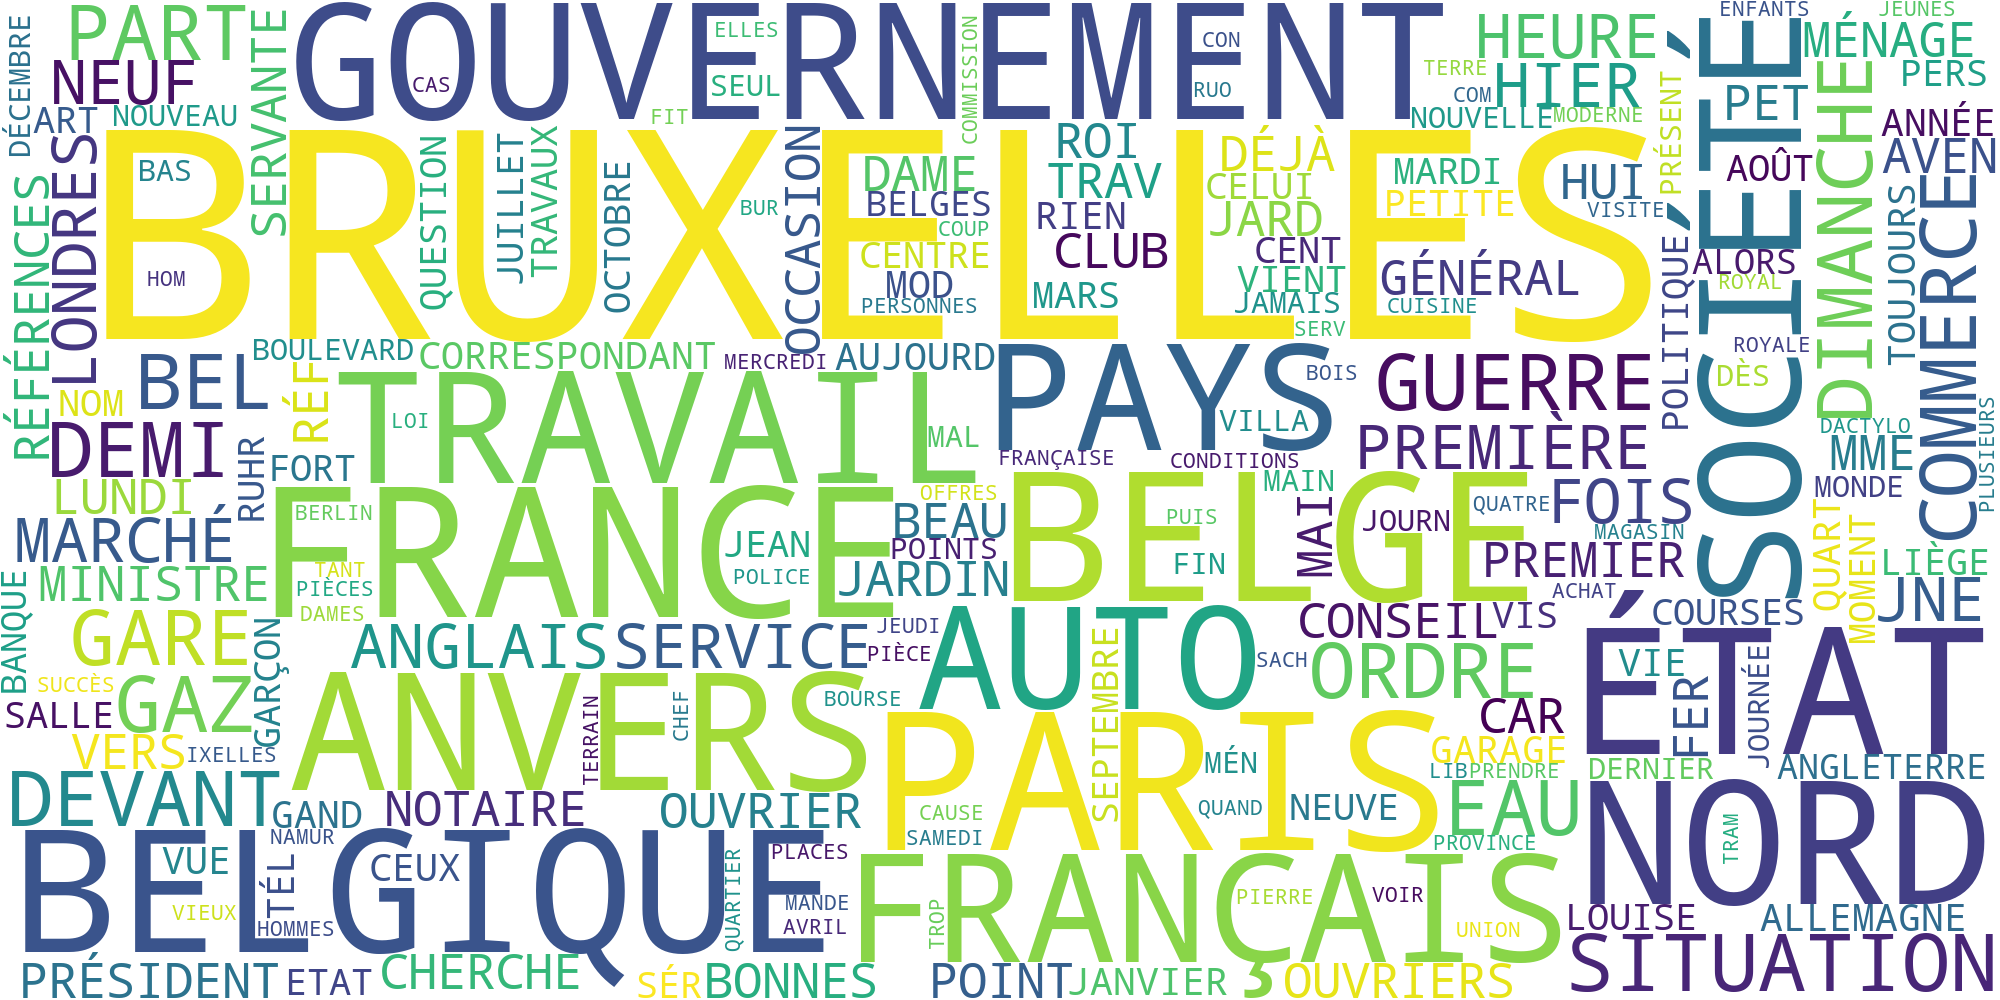

In [89]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}_v5.png"))
Image(filename=os.path.join(temp_path, f"{year}_v5.png"))